# Music Listener Profiles — EDA and Clustering

**Project track:** Clustering  
**Dataset file:** `SpotifyDataAnalysis.csv`  
**Dataset size:** 5,000 rows × 18 columns (verify after loading)  
**Unit of analysis:** One row per user/listener.

## Project rule
Unlike regression and classification, clustering has **no labels during training**. This notebook does not use a target/ground-truth label to fit clusters. Any cluster descriptions are interpretations of the resulting groups, not labels used by the algorithms.

## Workflow
1. Load data and inspect structure, summary statistics, missing values, duplicates, distributions, and feature relationships.
2. Prepare features without using `user_id` as a behavioural feature.
3. Scale numeric features and one-hot encode categorical features.
4. Use an elbow curve to guide K-Means cluster count selection.
5. Fit K-Means and Agglomerative Clustering; compare linkage strategies.
6. Evaluate every tested clustering configuration using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.
7. Visualize clusters using PCA with 2 components (mandatory); optionally use t-SNE.


## 1. Imports and configuration

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42
DATA_PATH = Path("../data/SpotifyDataAnalysis.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/SpotifyDataAnalysis.csv")

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Loaded: C:\Users\kavin\OneDrive\Desktop\ml_capstone\data\SpotifyDataAnalysis.csv
Rows: 5,000 | Columns: 18


,user_id,country,age,signup_date,subscription_type,subscription_status,months_inactive,inactive_3_months_flag,ad_interaction,ad_conversion_to_subscription,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,favorite_genre,most_liked_feature,desired_future_feature,primary_device,playlists_created,avg_skips_per_day
0,1,France,25,19/8/2021,Premium Duo,Active,0,0,No,No,4,10.13,Bollywood,Radio,Concert Alerts,Tablet,7,8
1,2,Indonesia,20,6/6/2022,Premium Family,Active,0,0,Yes,No,5,11.63,Latin,Podcasts,Lyrics Translation,Mobile,7,6
2,3,Italy,53,4/1/2024,Premium Individual,Active,0,0,Yes,Yes,3,9.50,Bollywood,Lyrics,Better AI Recommendations,Desktop,6,5
3,4,Italy,48,26/8/2018,Premium Individual,Active,1,0,No,No,4,13.16,Electronic,Playlists,Social Listening,Smart Speaker,11,8
4,5,Australia,18,29/5/2020,Free,Active,0,0,No,No,4,12.70,Indie,Daily Mix,Lyrics Translation,Tablet,10,11


## 2. Dataset structure and data types

In [3]:
print("Shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\\nSummary statistics for all columns:")
display(df.describe(include="all").T)


Shape: (5000, 18)
\nColumn names:
['user_id', 'country', 'age', 'signup_date', 'subscription_type', 'subscription_status', 'months_inactive', 'inactive_3_months_flag', 'ad_interaction', 'ad_conversion_to_subscription', 'music_suggestion_rating_1_to_5', 'avg_listening_hours_per_week', 'favorite_genre', 'most_liked_feature', 'desired_future_feature', 'primary_device', 'playlists_created', 'avg_skips_per_day']
\nData types:


,dtype
user_id,int64
country,str
age,int64
signup_date,str
subscription_type,str
subscription_status,str
months_inactive,int64
inactive_3_months_flag,int64
ad_interaction,str
ad_conversion_to_subscription,str


\nSummary statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,5000.0,NaN,NaN,NaN,2500.5,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
country,5000,12,France,453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5000.0,NaN,NaN,NaN,37.9386,12.83926,16.0,27.0,38.0,49.0,60.0
signup_date,5000,2444,15/8/2025,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subscription_type,5000,5,Free,2195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subscription_status,5000,2,Active,4230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
months_inactive,5000.0,NaN,NaN,NaN,1.5328,1.960228,0.0,0.0,1.0,2.0,15.0
inactive_3_months_flag,5000.0,NaN,NaN,NaN,0.2152,0.411002,0.0,0.0,0.0,0.0,1.0
ad_interaction,5000,2,No,3294,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ad_conversion_to_subscription,5000,2,No,4556,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Missing-value analysis

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})
display(missing_summary)
print("Total missing cells:", int(df.isna().sum().sum()))


,missing_count,missing_percent
user_id,0,0.0
country,0,0.0
age,0,0.0
signup_date,0,0.0
subscription_type,0,0.0
subscription_status,0,0.0
months_inactive,0,0.0
inactive_3_months_flag,0,0.0
ad_interaction,0,0.0
ad_conversion_to_subscription,0,0.0


Total missing cells: 0


## 4. Duplicate analysis

In [5]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
if "user_id" in df.columns:
    print("Duplicate user_id values:", int(df["user_id"].duplicated().sum()))
    print("Unique user IDs:", int(df["user_id"].nunique()))


Exact duplicate rows: 0
Duplicate user_id values: 0
Unique user IDs: 5000


## 5. Date parsing and derived feature

In [6]:
eda = df.copy()

if "signup_date" in eda.columns:
    eda["signup_date"] = pd.to_datetime(
        eda["signup_date"], dayfirst=True, errors="coerce"
    )
    valid_dates = eda["signup_date"].notna().sum()
    print(f"Parsed signup dates: {valid_dates:,}/{len(eda):,}")
    if valid_dates:
        reference_date = eda["signup_date"].max()
        eda["signup_tenure_days"] = (reference_date - eda["signup_date"]).dt.days
        print("Observed signup date range:", eda["signup_date"].min(), "to", reference_date)
        print("Tenure is calculated relative to the latest date in this dataset.")
        display(eda[["signup_date", "signup_tenure_days"]].head())


Parsed signup dates: 5,000/5,000
Observed signup date range: 2018-01-01 00:00:00 to 2026-03-01 00:00:00
Tenure is calculated relative to the latest date in this dataset.


,signup_date,signup_tenure_days
0,2021-08-19,1655
1,2022-06-06,1364
2,2024-01-04,787
3,2018-08-26,2744
4,2020-05-29,2102


## 6. Numeric feature distributions and outlier inspection

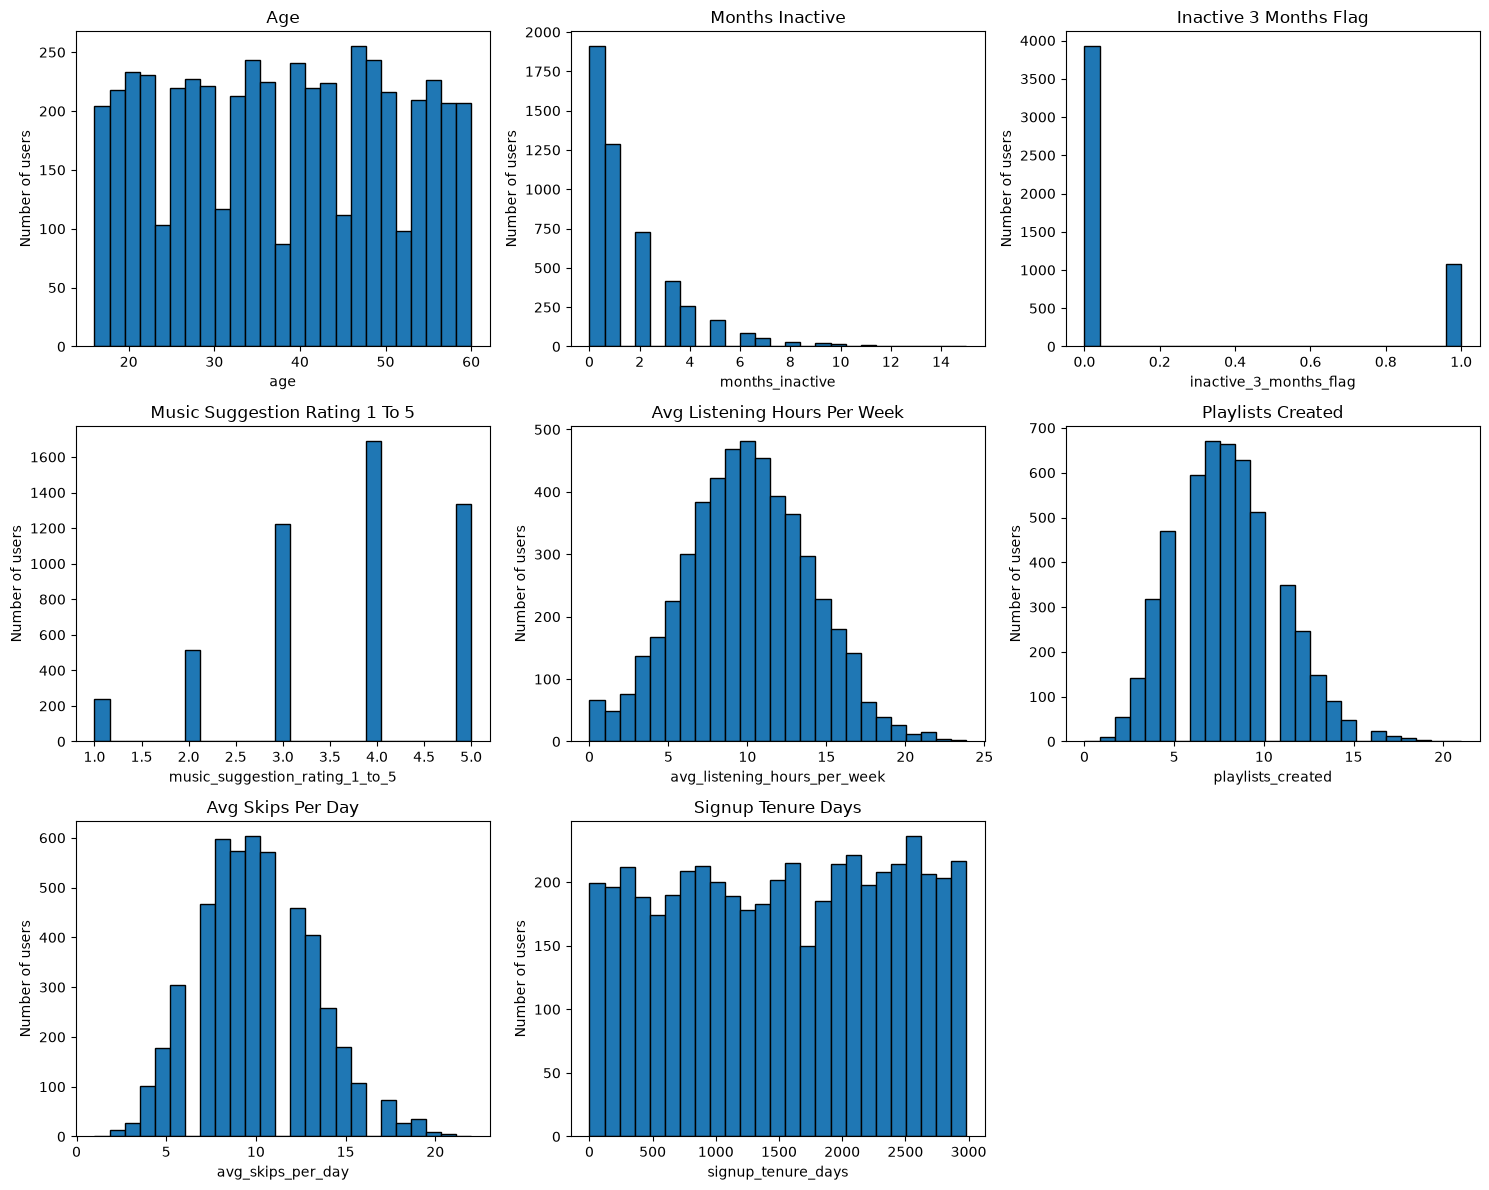

,count,mean,std,min,25%,50%,75%,max
age,5000.0,37.938600,12.839260,16.0,27.00,38.00,49.00,60.00
months_inactive,5000.0,1.532800,1.960228,0.0,0.00,1.00,2.00,15.00
inactive_3_months_flag,5000.0,0.215200,0.411002,0.0,0.00,0.00,0.00,1.00
music_suggestion_rating_1_to_5,5000.0,3.675000,1.115358,1.0,3.00,4.00,5.00,5.00
avg_listening_hours_per_week,5000.0,9.973416,4.008657,0.0,7.23,9.94,12.73,23.85
playlists_created,5000.0,8.024000,2.881299,0.0,6.00,8.00,10.00,21.00
avg_skips_per_day,5000.0,10.057400,3.188752,1.0,8.00,10.00,12.00,22.00
signup_tenure_days,5000.0,1516.944000,871.103842,0.0,757.00,1533.00,2290.00,2981.00


In [7]:
numeric_cols = eda.select_dtypes(include=np.number).columns.tolist()
plot_cols = [c for c in numeric_cols if c != "user_id"]

if plot_cols:
    ncols = 3
    nrows = int(np.ceil(len(plot_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, plot_cols):
        ax.hist(eda[col].dropna(), bins=25, edgecolor="black")
        ax.set_title(col.replace("_", " ").title())
        ax.set_xlabel(col)
        ax.set_ylabel("Number of users")
    for ax in axes[len(plot_cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

display(eda[plot_cols].describe().T)


## 7. Categorical feature distributions

C:\Users\kavin\AppData\Local\Temp\ipykernel_28064\1891164072.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = eda.select_dtypes(include=["object", "category"]).columns.tolist()


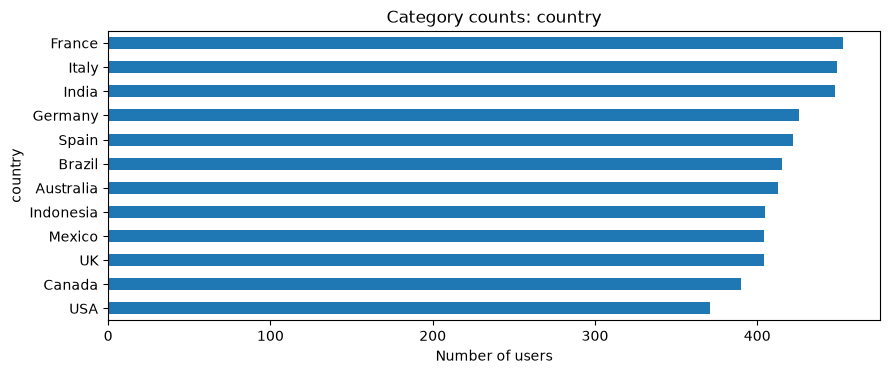

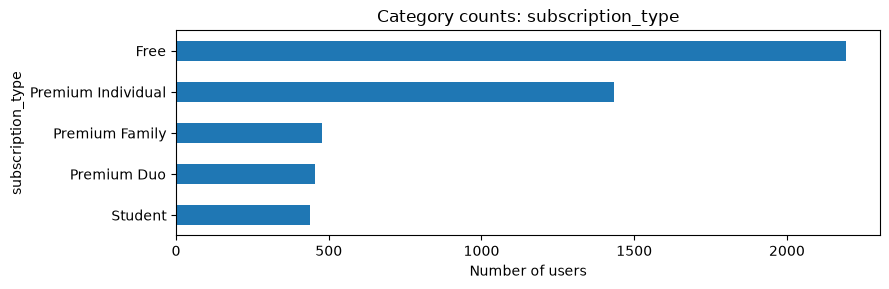

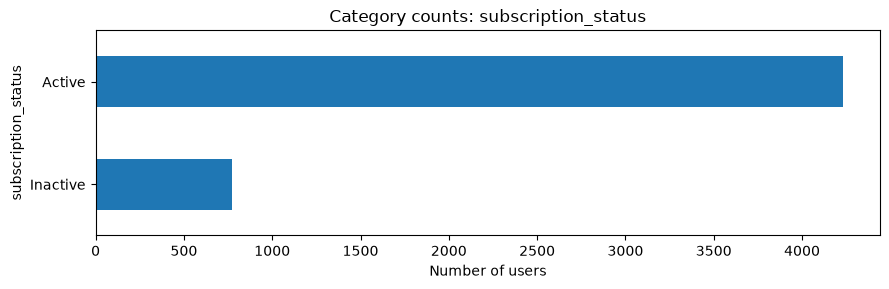

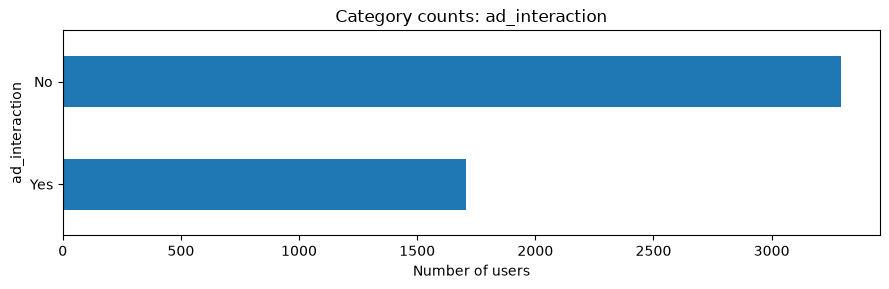

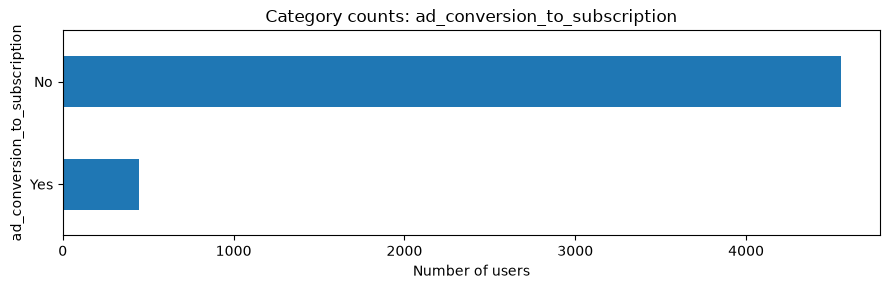

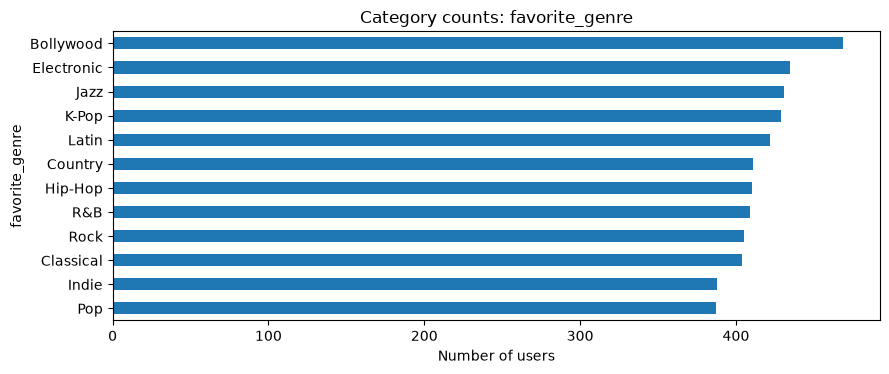

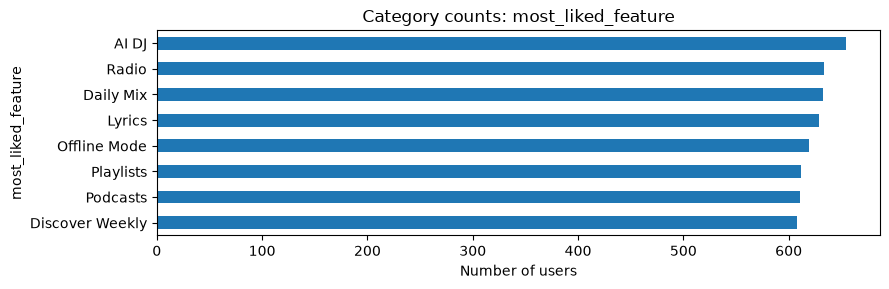

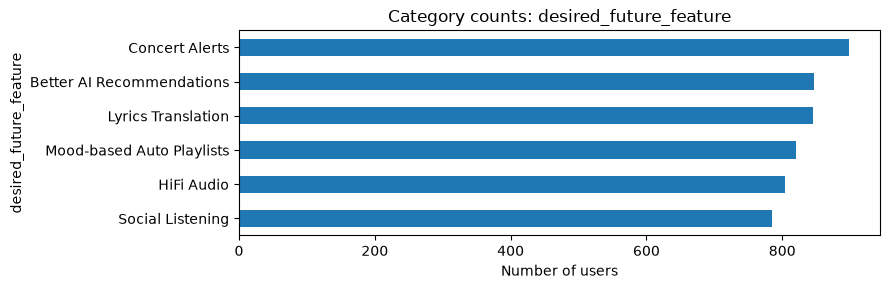

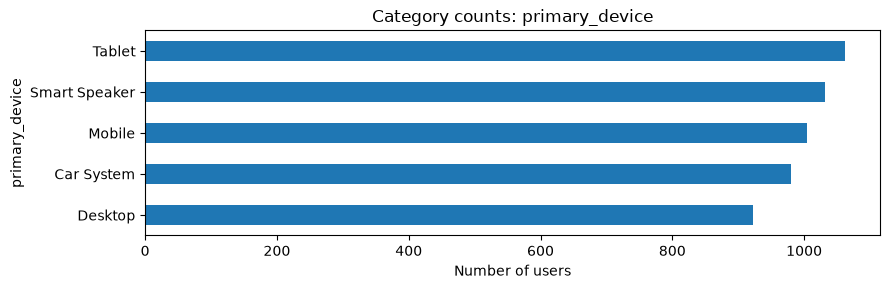

In [8]:
categorical_cols = eda.select_dtypes(include=["object", "category"]).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != "user_id"]

for col in categorical_cols:
    counts = eda[col].fillna("Missing").value_counts().head(15)
    plt.figure(figsize=(9, max(3, 0.32 * len(counts))))
    counts.sort_values().plot(kind="barh")
    plt.title(f"Category counts: {col}")
    plt.xlabel("Number of users")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


## 8. Correlation analysis

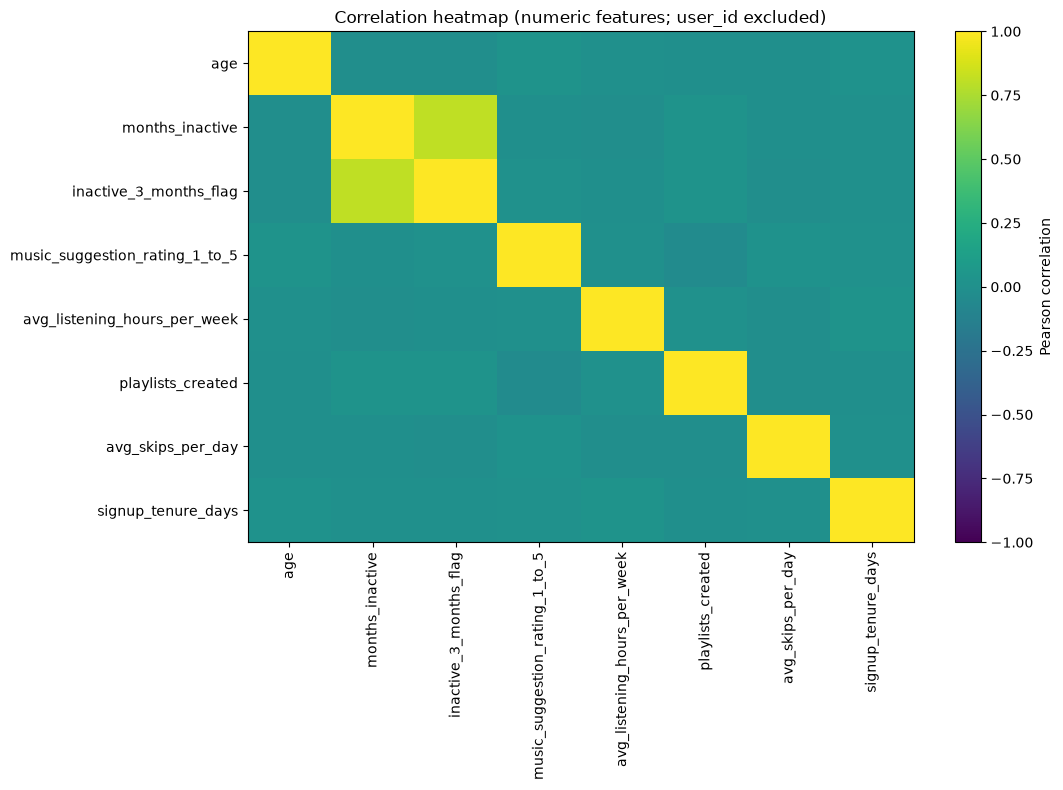

,age,months_inactive,inactive_3_months_flag,music_suggestion_rating_1_to_5,avg_listening_hours_per_week,playlists_created,avg_skips_per_day,signup_tenure_days
age,1.00,-0.02,-0.01,0.03,0.00,-0.00,-0.01,0.02
months_inactive,-0.02,1.00,0.81,-0.00,-0.01,0.03,-0.01,0.00
inactive_3_months_flag,-0.01,0.81,1.00,0.01,-0.00,0.03,-0.01,0.01
music_suggestion_rating_1_to_5,0.03,-0.00,0.01,1.00,0.00,-0.03,0.02,0.01
avg_listening_hours_per_week,0.00,-0.01,-0.00,0.00,1.00,0.01,-0.01,0.02
playlists_created,-0.00,0.03,0.03,-0.03,0.01,1.00,-0.01,-0.00
avg_skips_per_day,-0.01,-0.01,-0.01,0.02,-0.01,-0.01,1.00,0.00
signup_tenure_days,0.02,0.00,0.01,0.01,0.02,-0.00,0.00,1.00


In [9]:
corr_cols = [
    c for c in eda.select_dtypes(include=np.number).columns
    if c not in {"user_id"}
]
corr = eda[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Correlation heatmap (numeric features; user_id excluded)")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()
display(corr.round(2))


## 9. Relationships between behavioural features

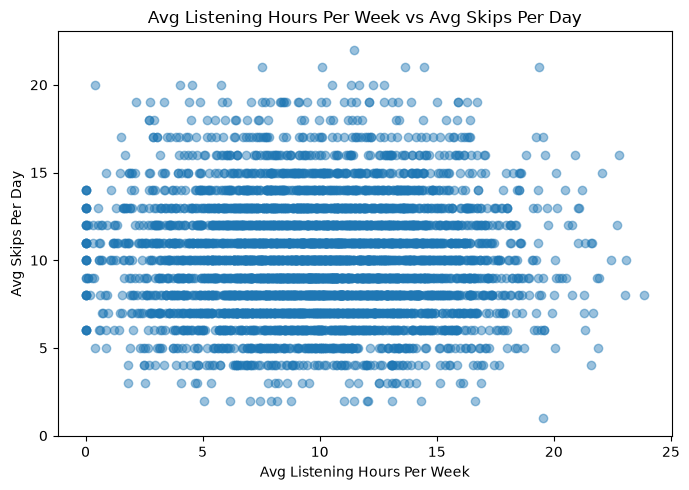

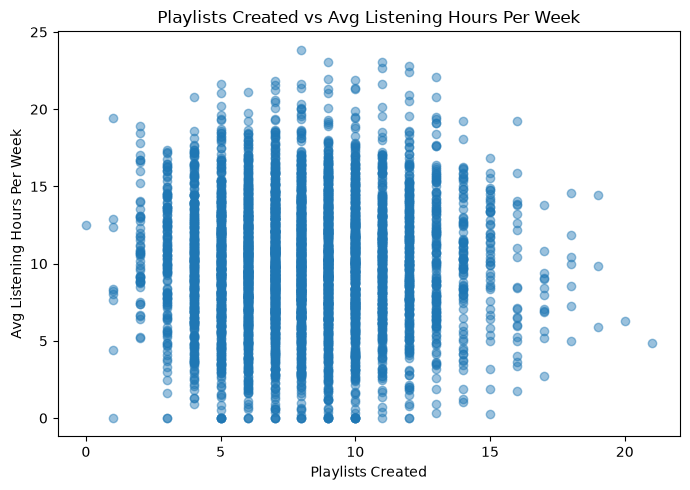

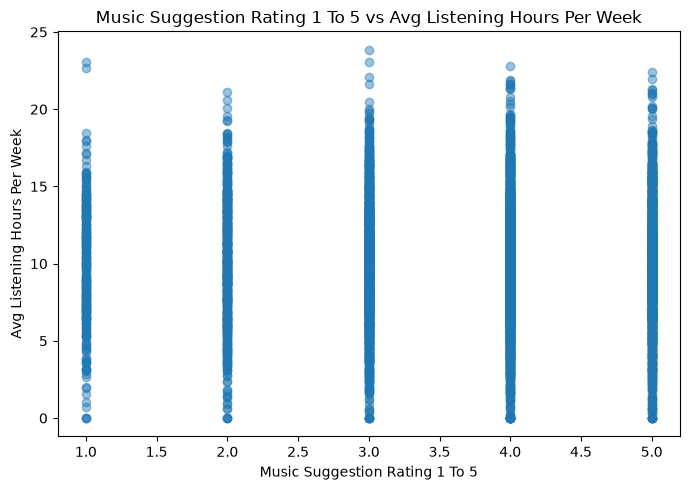

In [10]:
scatter_pairs = [
    ("avg_listening_hours_per_week", "avg_skips_per_day"),
    ("playlists_created", "avg_listening_hours_per_week"),
    ("music_suggestion_rating_1_to_5", "avg_listening_hours_per_week"),
]
for x, y in scatter_pairs:
    if {x, y}.issubset(eda.columns):
        plt.figure(figsize=(7, 5))
        plt.scatter(eda[x], eda[y], alpha=0.45)
        plt.xlabel(x.replace("_", " ").title())
        plt.ylabel(y.replace("_", " ").title())
        plt.title(f"{x.replace('_', ' ').title()} vs {y.replace('_', ' ').title()}")
        plt.tight_layout()
        plt.show()


## 10. Prepare features for unsupervised clustering

- `user_id` is an identifier, so it is excluded.
- `signup_date` is converted to `signup_tenure_days` and the raw date is dropped.
- `inactive_3_months_flag` is excluded because it overlaps with `months_inactive`; keeping both can double-weight inactivity information.
- Numeric features are median-imputed and standardized.
- Categorical features are most-frequent imputed and one-hot encoded.
- No ground-truth labels are used in preprocessing or model fitting.

Review the selected features and adjust them only with a clear justification.


In [11]:
cluster_df = eda.copy()

# Keep parsed tenure rather than the raw date string.
cluster_df = cluster_df.drop(columns=["signup_date"], errors="ignore")

# Exclude identifiers and a redundant flag.
excluded_cols = ["user_id", "inactive_3_months_flag"]
X_raw = cluster_df.drop(columns=excluded_cols, errors="ignore")

numeric_features = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Excluded identifier/redundant columns:", excluded_cols)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_processed = preprocessor.fit_transform(X_raw)
print("Processed feature matrix shape:", X_processed.shape)


Excluded identifier/redundant columns: ['user_id', 'inactive_3_months_flag']
Numeric features: ['age', 'months_inactive', 'music_suggestion_rating_1_to_5', 'avg_listening_hours_per_week', 'playlists_created', 'avg_skips_per_day', 'signup_tenure_days']
Categorical features: ['country', 'subscription_type', 'subscription_status', 'ad_interaction', 'ad_conversion_to_subscription', 'favorite_genre', 'most_liked_feature', 'desired_future_feature', 'primary_device']
Processed feature matrix shape: (5000, 61)


C:\Users\kavin\AppData\Local\Temp\ipykernel_28064\1861861309.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


## 11. K-Means — Elbow curve (inertia vs. k)

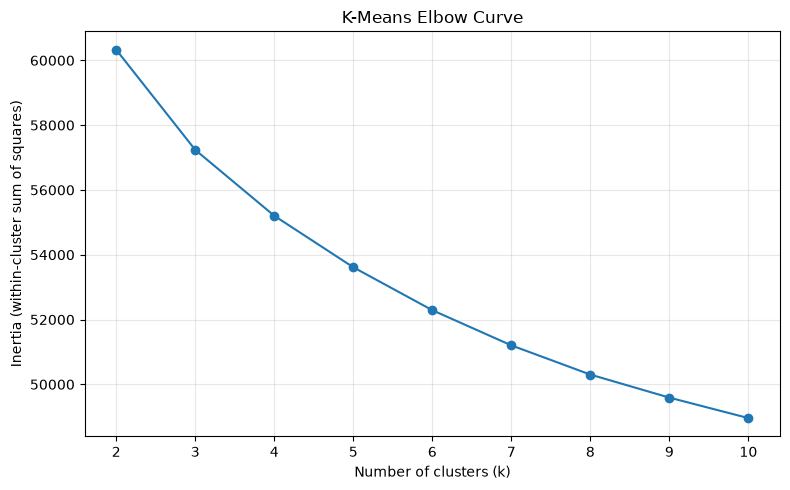

Choose k by looking for the bend/elbow in the curve. Do not choose k based only on inertia.


In [12]:
k_values = range(2, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("K-Means Elbow Curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Choose k by looking for the bend/elbow in the curve. Do not choose k based only on inertia.")
